# Data Mining Project — Student Performance Prediction

In [3]:
# Step: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve

In [4]:
df = pd.read_csv("student_performance_data.csv")

print(df.shape)
df.head()

(395, 33)


,school,sex,age,address,Pstatus,Medu,Fedu,Mjob,Fjob,reason,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,Pass
0,GP,M,20,R,A,0,2,other,at_home,other,...,3,5,5,1,4,9,16,0,5,0
1,MS,M,22,R,A,2,4,teacher,teacher,home,...,5,2,5,4,5,64,4,15,3,0
2,GP,M,19,U,T,2,2,at_home,other,other,...,2,1,1,2,1,41,6,10,4,0
3,GP,M,18,U,A,1,2,health,at_home,reputation,...,2,1,2,5,2,84,18,19,6,0
4,GP,F,15,R,A,4,0,at_home,teacher,reputation,...,5,5,1,3,3,8,14,5,4,0


In [5]:
print("\nFirst rows:")
display(df.head())

print("\nStatistics:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)


First rows:


,school,sex,age,address,Pstatus,Medu,Fedu,Mjob,Fjob,reason,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,Pass
0,GP,M,20,R,A,0,2,other,at_home,other,...,3,5,5,1,4,9,16,0,5,0
1,MS,M,22,R,A,2,4,teacher,teacher,home,...,5,2,5,4,5,64,4,15,3,0
2,GP,M,19,U,T,2,2,at_home,other,other,...,2,1,1,2,1,41,6,10,4,0
3,GP,M,18,U,A,1,2,health,at_home,reputation,...,2,1,2,5,2,84,18,19,6,0
4,GP,F,15,R,A,4,0,at_home,teacher,reputation,...,5,5,1,3,3,8,14,5,4,0



Statistics:


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,Pass
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,18.382278,1.977215,2.017722,2.506329,2.450633,1.389873,3.017722,3.025316,3.005063,2.901266,2.994937,2.929114,46.324051,10.073418,10.108861,4.567089,0.134177
std,2.250367,1.432752,1.425721,1.138543,1.124019,1.101406,1.418582,1.406788,1.428490,1.431294,1.361164,1.421388,26.034559,5.921841,6.369805,4.304694,0.341275
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,1.000000,1.000000,1.000000,1.000000,0.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,22.500000,5.000000,4.000000,0.000000,0.000000
50%,18.000000,2.000000,2.000000,3.000000,2.000000,1.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,47.000000,10.000000,10.000000,4.000000,0.000000
75%,20.000000,3.000000,3.000000,4.000000,3.000000,2.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,69.000000,15.000000,16.000000,8.000000,0.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,92.000000,20.000000,20.000000,20.000000,1.000000



Missing values:
school        0
sex           0
age           0
address       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
Pass          0
dtype: int64

Data types:
school        object
sex           object
age            int64
address       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet 

In [6]:
# Step: Create Pass/Fail column
df['Pass'] = df['G3'].apply(lambda x: 1 if x >= 10 else 0)
print(df)

    school sex  age address Pstatus  Medu  Fedu     Mjob     Fjob      reason  \
0       GP   M   20       R       A     0     2    other  at_home       other   
1       MS   M   22       R       A     2     4  teacher  teacher        home   
2       GP   M   19       U       T     2     2  at_home    other       other   
3       GP   M   18       U       A     1     2   health  at_home  reputation   
4       GP   F   15       R       A     4     0  at_home  teacher  reputation   
..     ...  ..  ...     ...     ...   ...   ...      ...      ...         ...   
390     GP   F   20       U       T     1     0    other  teacher      course   
391     GP   F   22       U       T     1     0    other    other      course   
392     MS   M   22       R       T     1     2    other  teacher       other   
393     MS   M   18       R       A     3     0   health    other       other   
394     GP   F   22       U       A     0     3  at_home  teacher        home   

     ... freetime  goout  D

In [7]:
# Step: Check Pass column values
df['Pass'].value_counts()

Pass
0    342
1     53
Name: count, dtype: int64

 # Exploratory Data Analysis (EDA)

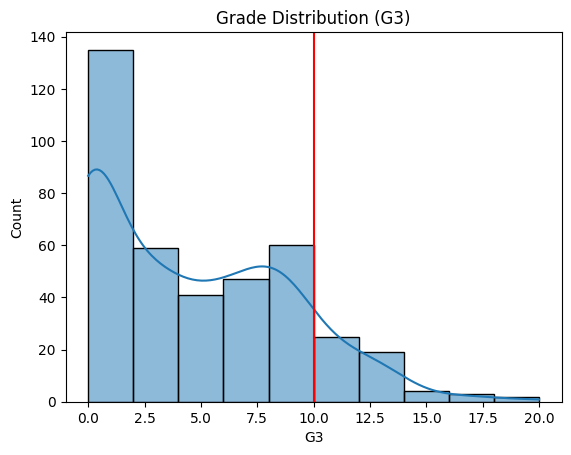

In [8]:
# Step: Distribution of final grades
sns.histplot(df['G3'], kde=True)
plt.axvline(10, color='red')
plt.title("Grade Distribution (G3)")
plt.show()

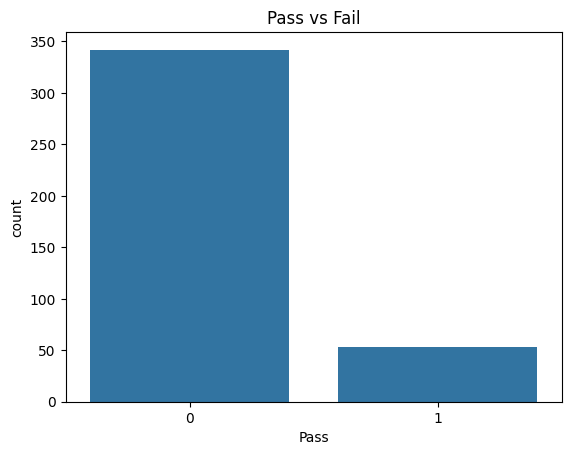

In [9]:
# Step: Pass vs Fail count
sns.countplot(x='Pass', data=df)
plt.title("Pass vs Fail")
plt.show()

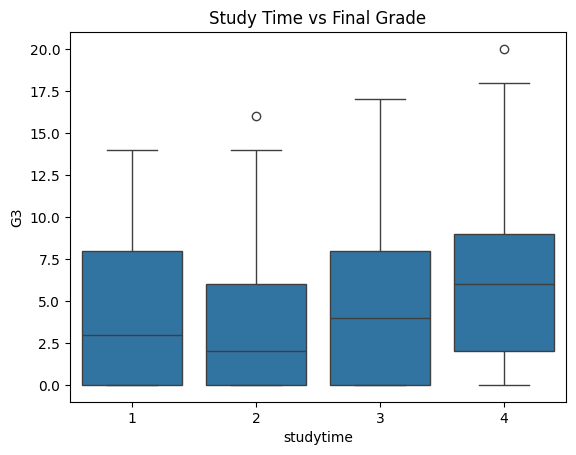

In [10]:
# Step: Study time vs grade
sns.boxplot(x='studytime', y='G3', data=df)
plt.title("Study Time vs Final Grade")
plt.show()

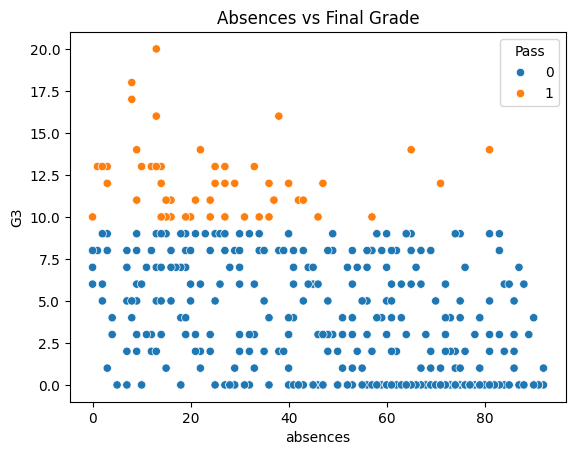

In [11]:
# Step: Absences vs grade
sns.scatterplot(x='absences', y='G3', hue='Pass', data=df)
plt.title("Absences vs Final Grade")
plt.show()

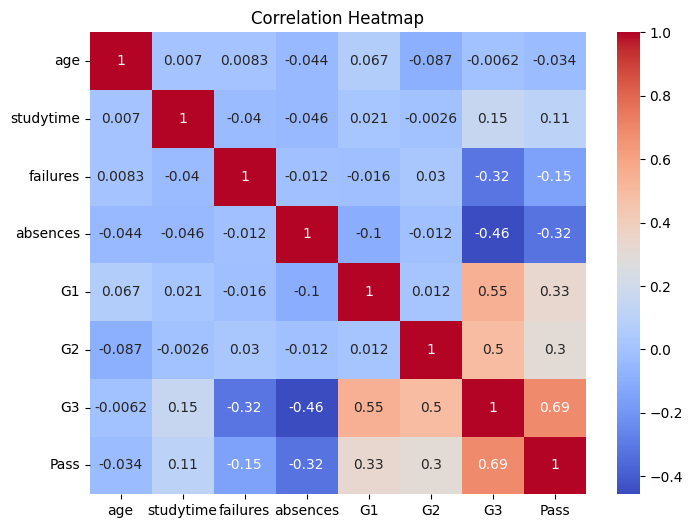

In [12]:
# Step: Correlation heatmap
cols = ['age','studytime','failures','absences','G1','G2','G3','Pass']

plt.figure(figsize=(8,6))
sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.savefig("chart5_correlation_heatmap.png")
plt.show()

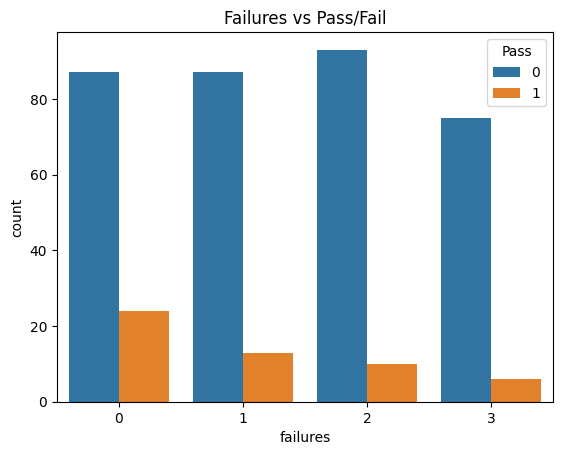

In [13]:

# Step: Failures vs Pass/Fail
sns.countplot(x='failures', hue='Pass', data=df)
plt.title("Failures vs Pass/Fail")
plt.show()

#  Data Preprocessing
Preprocessing = preparing raw data so the algorithms can use it correctly.

In [14]:
# Step 1: Import pandas
#import pandas as pd

# Step 2: Load dataset
#url = "student_performance_data.csv"
#df = pd.read_csv(url, sep=',')

#df.head()

In [15]:
# Select Features (X) — choose which columns to use as input
X = df[['age','studytime','failures','absences','G1','G2','Medu','Fedu','famrel','freetime','goout']]
X.head()

,age,studytime,failures,absences,G1,G2,Medu,Fedu,famrel,freetime,goout
0,20,1,1,9,16,0,0,2,2,3,5
1,22,3,0,64,4,15,2,4,3,5,2
2,19,2,1,41,6,10,2,2,4,2,1
3,18,1,1,84,18,19,1,2,1,2,1
4,15,2,2,8,14,5,4,0,3,5,5


In [16]:
# Define Target (y) — the column we want to predict
y = df['Pass']
y.head()

0    0
1    0
2    0
3    0
4    0
Name: Pass, dtype: int64

In [17]:
# Train-Test Split — split data into 80% train and 20% test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Check sizes
print(X_train.shape, X_test.shape)

(316, 11) (79, 11)


In [18]:
# Feature Scaling — normalize values to the same scale (used for Naive Bayes)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled[:5]

array([[ 1.20015714,  1.32094858,  0.5597689 , -0.68340942,  1.65539087,
        -0.34518001, -0.65010942, -0.70166713, -0.78686978, -0.76191062,
        -1.43695016],
       [ 1.64528585,  1.32094858, -0.33359965,  1.12212299, -1.50485294,
        -1.60436481, -0.65010942, -0.70166713, -0.78686978,  1.36247546,
        -0.72966628],
       [ 1.20015714,  1.32094858,  1.45313744, -0.91891365,  0.3247619 ,
         1.54359719, -0.65010942, -1.39892125, -0.78686978, -0.76191062,
         1.39218536],
       [-0.58035768,  1.32094858,  1.45313744,  0.49411172, -1.67118156,
        -0.34518001, -1.34649782,  0.69284112,  0.65458442, -1.47003931,
         1.39218536],
       [-1.47061509,  0.43092779, -1.22696819, -1.54692492,  0.65741914,
         1.38619909,  1.43905577, -0.70166713, -0.06614268,  0.65434677,
         0.68490148]])

# Training the 3 Models
Algorithm 1: Decision Tree .              
Algorithm 2: Random Forest .          
Algorithm 3: Naive Bayes 

In [19]:
# Step: Train Decision Tree
from sklearn.tree import DecisionTreeClassifier

print("TRAINING ALGORITHM 1 — DECISION TREE 🌳")

dt_model = DecisionTreeClassifier(
    max_depth=4,
    min_samples_split=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

# Get feature names
features = X.columns

# Safe root feature extraction
root_index = dt_model.tree_.feature[0]

if root_index != -2:
    root_feature = features[root_index]
else:
    root_feature = "No split (single node)"

# Output
print(f"✅ Decision Tree trained successfully!")
print(f"Tree depth  : {dt_model.get_depth()} levels")
print(f"Leaf nodes  : {dt_model.get_n_leaves()}")
print(f"Root feature: {root_feature}")
print("(The root split is the MOST important question)")


TRAINING ALGORITHM 1 — DECISION TREE 🌳
✅ Decision Tree trained successfully!
Tree depth  : 4 levels
Leaf nodes  : 12
Root feature: absences
(The root split is the MOST important question)


In [20]:
# Step: Import
from sklearn.ensemble import RandomForestClassifier

print("TRAINING ALGORITHM 2 — RANDOM FOREST 🌲")

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    random_state=42
)

rf_model.fit(X_train, y_train)
# .fit() builds all 100 trees and stores them internally

print(f"✅  Random Forest trained successfully!")
print(f"   Number of trees     : {rf_model.n_estimators}")
print(f"   Features per split  : {rf_model.max_features}")
print(f"   Each tree max depth : {rf_model.max_depth}")
print("\n   The forest = 100 independent decision trees voting together")


TRAINING ALGORITHM 2 — RANDOM FOREST 🌲
✅  Random Forest trained successfully!
   Number of trees     : 100
   Features per split  : sqrt
   Each tree max depth : 6

   The forest = 100 independent decision trees voting together


In [21]:
# Step: Import Naive Bayes
from sklearn.naive_bayes import GaussianNB

print("TRAINING ALGORITHM 3 — NAIVE BAYES (GaussianNB) 🔵")

nb_model = GaussianNB()

# Step: Train model
nb_model.fit(X_train_scaled, y_train)

print(f"✅ Naive Bayes trained successfully!")
print(f"Classes: {nb_model.classes_}")

print(f"P(Fail=0): {nb_model.class_prior_[0]:.4f}")
print(f"P(Pass=1): {nb_model.class_prior_[1]:.4f}")


TRAINING ALGORITHM 3 — NAIVE BAYES (GaussianNB) 🔵
✅ Naive Bayes trained successfully!
Classes: [0 1]
P(Fail=0): 0.8544
P(Pass=1): 0.1456


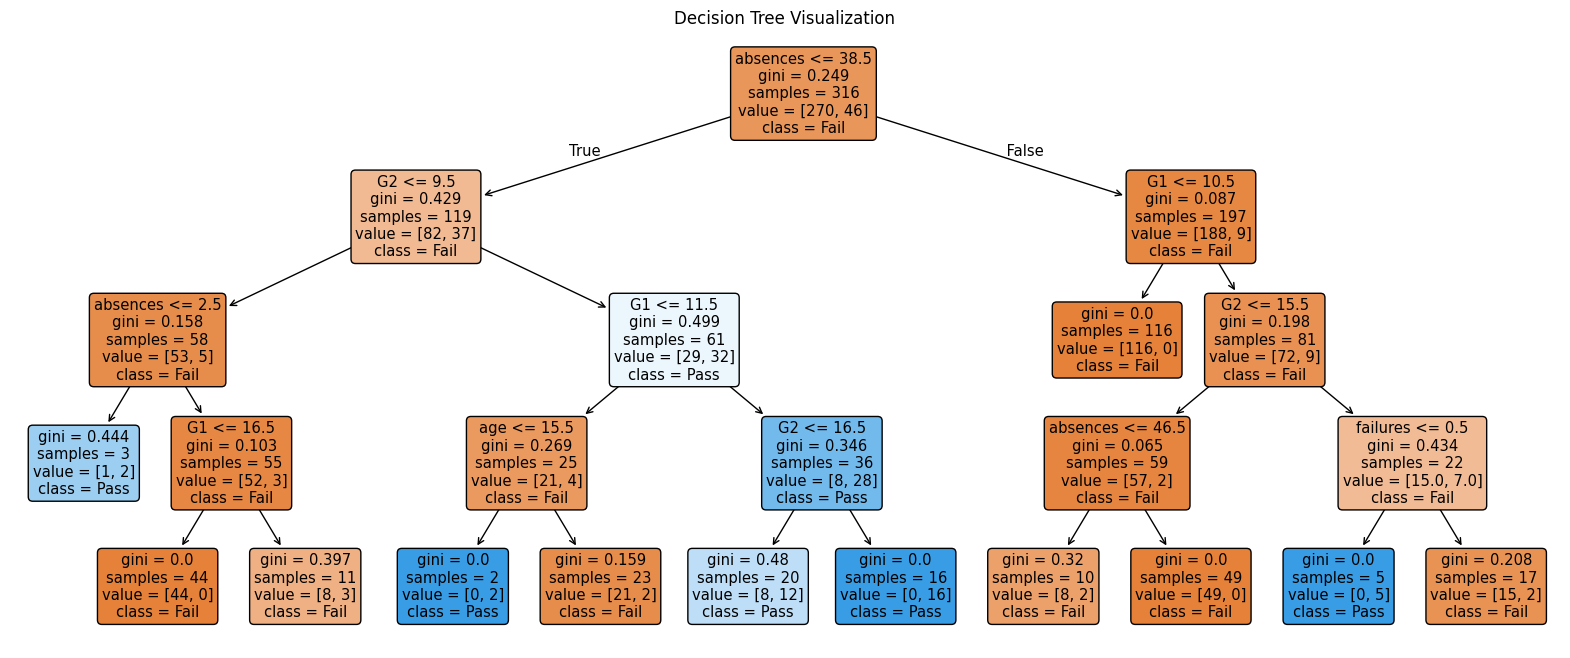

In [22]:
# Step: Visualize Decision Tree
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20,8))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=["Fail", "Pass"],
    filled=True,
    rounded=True
)

plt.title("Decision Tree Visualization")
plt.show()

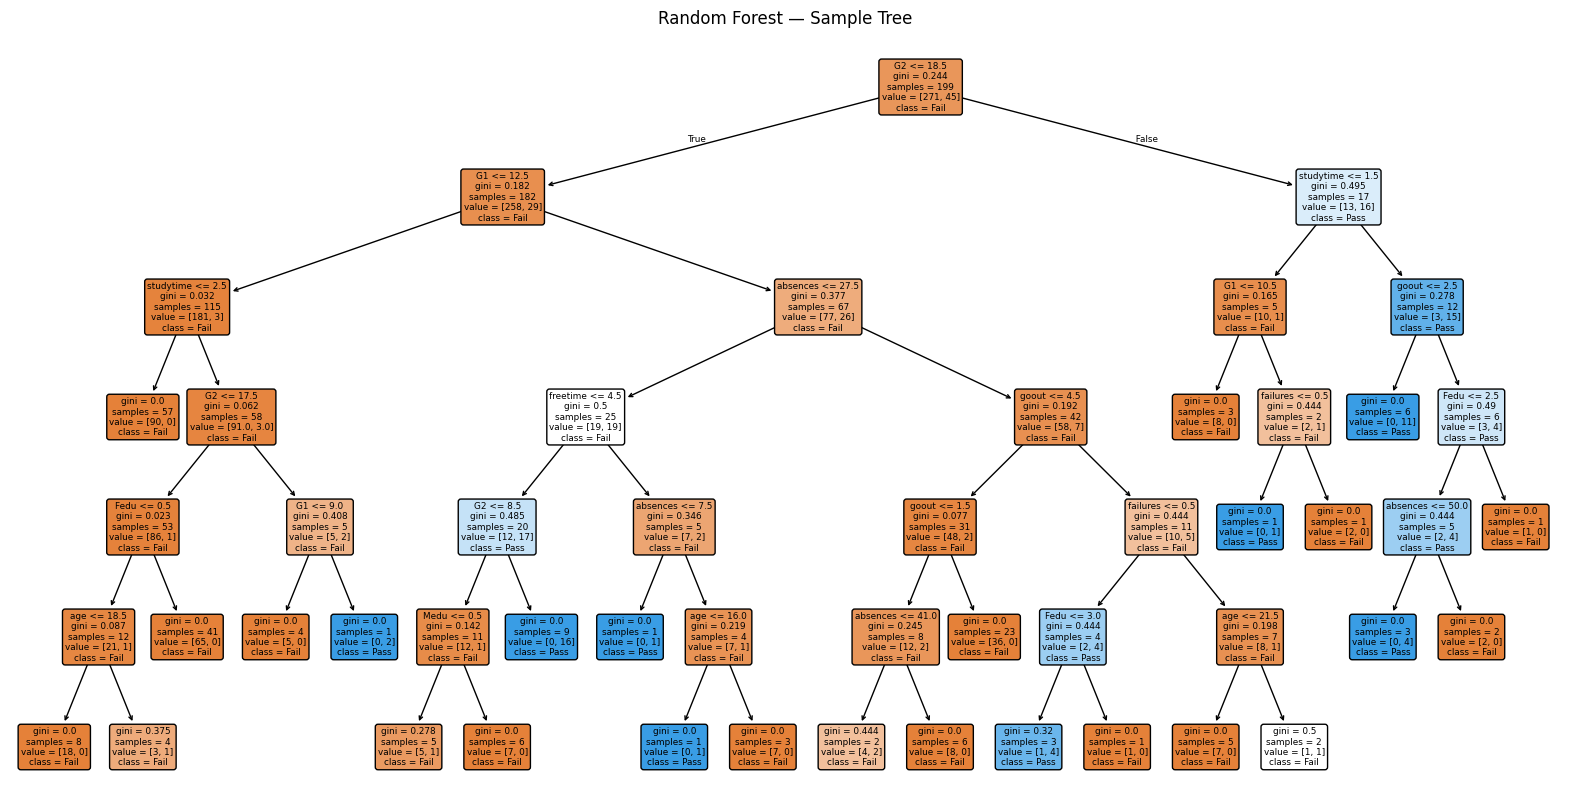

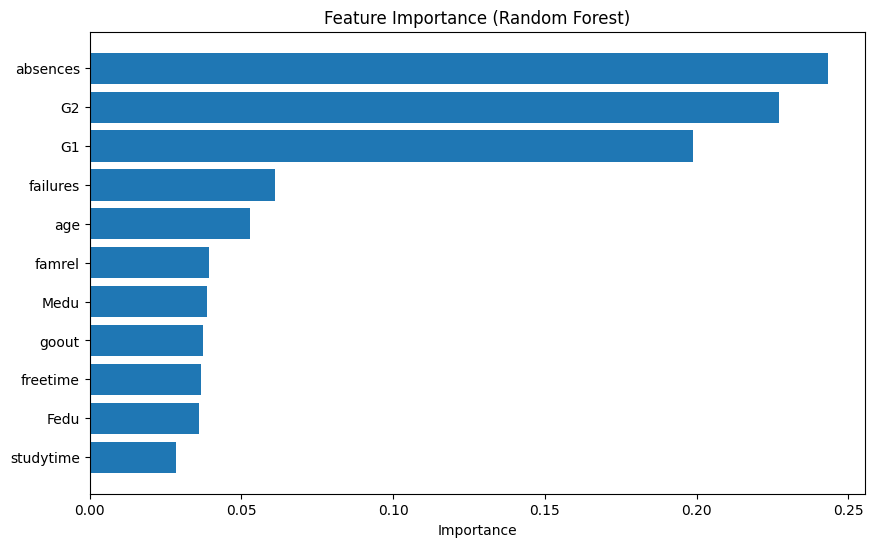

In [23]:
# Step: Visualize one tree from Random Forest
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20,10))

plot_tree(
    rf_model.estimators_[0],   # first tree in forest
    feature_names=X.columns,
    class_names=["Fail", "Pass"],
    filled=True,
    rounded=True
)

plt.title("Random Forest — Sample Tree")
plt.show()




# Step: Feature importance
import pandas as pd
import matplotlib.pyplot as plt

importance = rf_model.feature_importances_

# Create dataframe for sorting
imp_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(10,6))
plt.barh(imp_df['Feature'], imp_df['Importance'])
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance")
plt.show()

In [24]:
#Naive Bayes (2 visuals)
#Probability output visual 1
nb_model.predict_proba(X_test_scaled)



array([[9.99995863e-01, 4.13669162e-06],
       [9.93478664e-01, 6.52133555e-03],
       [9.95814533e-01, 4.18546731e-03],
       [9.98212454e-01, 1.78754629e-03],
       [8.04859116e-01, 1.95140884e-01],
       [5.24188868e-01, 4.75811132e-01],
       [9.99062698e-01, 9.37302325e-04],
       [9.99999575e-01, 4.25194486e-07],
       [9.98492642e-01, 1.50735788e-03],
       [9.99185807e-01, 8.14192962e-04],
       [3.92301039e-01, 6.07698961e-01],
       [9.98802006e-01, 1.19799441e-03],
       [7.02906268e-01, 2.97093732e-01],
       [9.33855279e-01, 6.61447211e-02],
       [2.11114642e-01, 7.88885358e-01],
       [8.25220220e-01, 1.74779780e-01],
       [9.87280072e-01, 1.27199283e-02],
       [9.98806726e-01, 1.19327368e-03],
       [9.99545376e-01, 4.54624179e-04],
       [9.80084413e-01, 1.99155873e-02],
       [9.99605596e-01, 3.94404032e-04],
       [9.99998422e-01, 1.57774762e-06],
       [9.99002244e-01, 9.97756108e-04],
       [9.65470969e-01, 3.45290308e-02],
       [9.741934

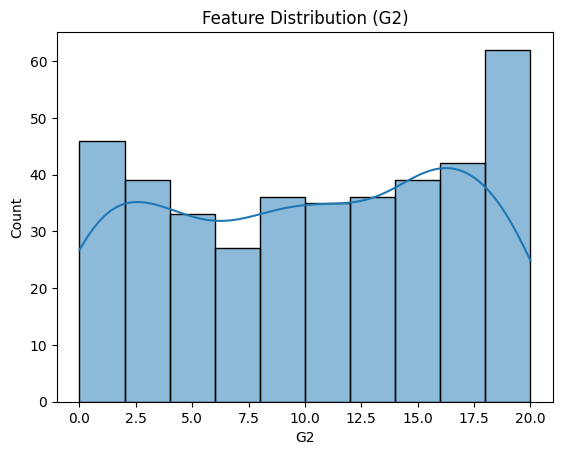

In [25]:
#Feature distribution (visual 2)
# Example feature distribution
sns.histplot(df['G2'], kde=True)
plt.title("Feature Distribution (G2)")
plt.show()


# Making Predictions
Now we give each trained model the test data (students it has NEVER seen)
and ask it to predict whether each student will Pass or Fail.

In [27]:
# ── Class Label Predictions ───────────────────────────────────────────────────
# .predict() returns 0 (Fail) or 1 (Pass) for each test student

dt_pred = dt_model.predict(X_test)          # Decision Tree predictions
rf_pred = rf_model.predict(X_test)          # Random Forest predictions
nb_pred = nb_model.predict(X_test_scaled)   # Naive Bayes predictions (SCALED input!)

# ── Probability Predictions (for ROC Curve) ───────────────────────────────────
# .predict_proba() returns TWO probabilities: [P(Fail), P(Pass)]
# We take [:,1] to get only the P(Pass) value

dt_prob = dt_model.predict_proba(X_test)[:, 1]         # P(Pass) for each student
rf_prob = rf_model.predict_proba(X_test)[:, 1]
nb_prob = nb_model.predict_proba(X_test_scaled)[:, 1]

# ── Show sample predictions ────────────────────────────────────────────────────
print("=" * 65)
print("SAMPLE PREDICTIONS — First 15 test students")
print("=" * 65)
print("\nComparison: What did each model predict vs the actual answer?")
print()

results_preview = pd.DataFrame({
    'Actual'       : list(y_test[:15]),
    'Decision Tree': list(dt_pred[:15]),
    'Random Forest': list(rf_pred[:15]),
    'Naive Bayes'  : list(nb_pred[:15]),
    'DT Prob(Pass)': [f"{p:.2f}" for p in dt_prob[:15]],
    'RF Prob(Pass)': [f"{p:.2f}" for p in rf_prob[:15]],
}).reset_index(drop=True)

results_preview.index += 1  # start row numbers at 1
print(results_preview.to_string())
print("\nLegend: 0 = Fail,  1 = Pass")
print("Correct predictions are where model column = Actual column")


SAMPLE PREDICTIONS — First 15 test students

Comparison: What did each model predict vs the actual answer?

    Actual  Decision Tree  Random Forest  Naive Bayes DT Prob(Pass) RF Prob(Pass)
1        0              0              0            0          0.00          0.01
2        0              0              0            0          0.00          0.05
3        0              0              0            0          0.00          0.02
4        0              0              0            0          0.00          0.14
5        0              0              0            0          0.12          0.17
6        0              0              0            0          0.09          0.32
7        0              0              0            0          0.09          0.08
8        0              0              0            0          0.00          0.05
9        0              0              0            0          0.00          0.01
10       0              0              0            0          0.00     

# Model Evaluation (Measuring Performance)
After making predictions, we measure how good each model is using metrics.

In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
    classification_report
)

def evaluate_model(model_name, y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)

    print(f"\nMODEL: {model_name}")
    print(f"Accuracy: {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"AUC: {roc_auc:.4f}")

    return {'acc': acc, 'auc': roc_auc}

In [36]:
print("MODEL EVALUATION RESULTS")

dt_results = evaluate_model("Decision Tree", y_test, dt_pred, dt_prob)
rf_results = evaluate_model("Random Forest", y_test, rf_pred, rf_prob)
nb_results = evaluate_model("Naive Bayes", y_test, nb_pred, nb_prob)


MODEL EVALUATION RESULTS

MODEL: Decision Tree
Accuracy: 0.9241
Precision: 0.5385
Recall: 1.0000
F1 Score: 0.7000
AUC: 0.9683

MODEL: Random Forest
Accuracy: 0.9241
Precision: 1.0000
Recall: 0.1429
F1 Score: 0.2500
AUC: 0.9782

MODEL: Naive Bayes
Accuracy: 0.9620
Precision: 1.0000
Recall: 0.5714
F1 Score: 0.7273
AUC: 0.9821


# Result Visualizations
Now we draw charts to compare all 3 models visually:

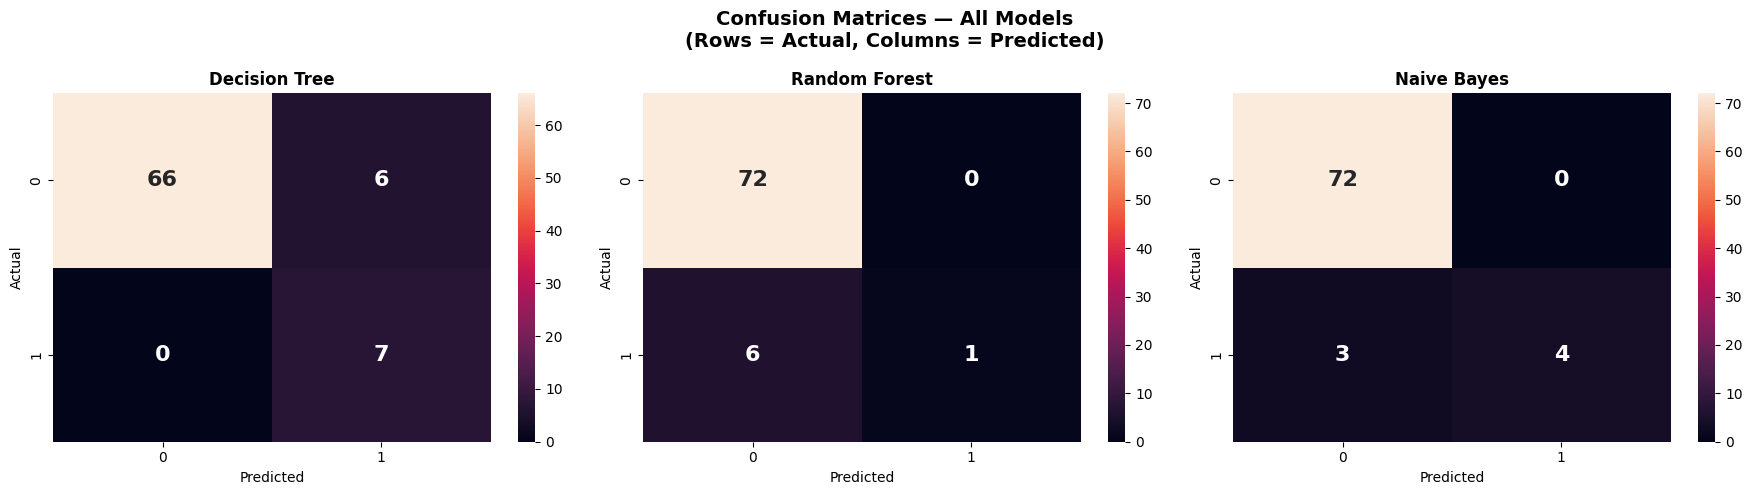

In [43]:
# Imports
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Models
models = [
    ("Decision Tree", dt_pred),
    ("Random Forest", rf_pred),
    ("Naive Bayes", nb_pred)
]

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

fig.suptitle(
    "Confusion Matrices — All Models\n(Rows = Actual, Columns = Predicted)",
    fontsize=14,
    fontweight='bold'
)

for i, (name, pred) in enumerate(models):
    cm = confusion_matrix(y_test, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='rocket',   # ✅ EXACT color palette
        annot_kws={"size": 16, "weight": "bold"},
        xticklabels=['0', '1'],
        yticklabels=['0', '1'],
        cbar=True,
        ax=axes[i]
    )

    axes[i].set_title(name, fontsize=12, fontweight='bold')
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()

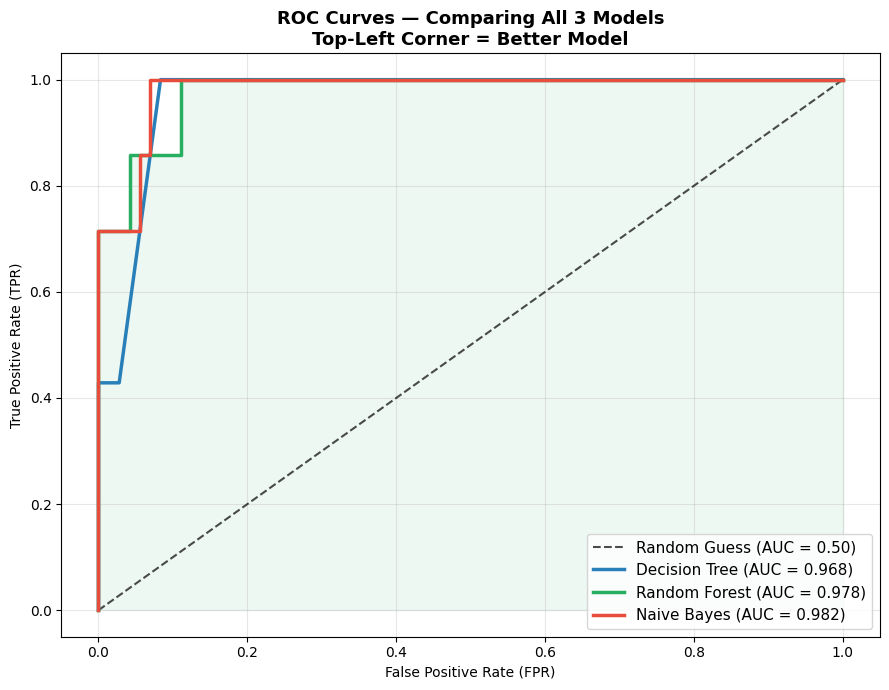

✅ ROC Curves displayed!


In [45]:
# Imports
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# --- Compute ROC data for each model ---
# Decision Tree
dt_fpr, dt_tpr, _ = roc_curve(y_test, dt_prob)
dt_auc = auc(dt_fpr, dt_tpr)

# Random Forest
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
rf_auc = auc(rf_fpr, rf_tpr)

# Naive Bayes
nb_fpr, nb_tpr, _ = roc_curve(y_test, nb_prob)
nb_auc = auc(nb_fpr, nb_tpr)

# --- Plot ---
fig, ax = plt.subplots(figsize=(9, 7))

# Baseline (random)
ax.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Guess (AUC = 0.50)', alpha=0.7)

# Curves
ax.plot(dt_fpr, dt_tpr, color='#2980b9', linewidth=2.5,
        label=f"Decision Tree (AUC = {dt_auc:.3f})")

ax.plot(rf_fpr, rf_tpr, color='#27ae60', linewidth=2.5,
        label=f"Random Forest (AUC = {rf_auc:.3f})")

ax.plot(nb_fpr, nb_tpr, color='#e74c3c', linewidth=2.5,
        label=f"Naive Bayes (AUC = {nb_auc:.3f})")

# Optional highlight for RF
ax.fill_between(rf_fpr, rf_tpr, alpha=0.08, color='#27ae60')

# Labels & styling
ax.set_title("ROC Curves — Comparing All 3 Models\nTop-Left Corner = Better Model",
             fontsize=13, fontweight='bold')
ax.set_xlabel("False Positive Rate (FPR)")
ax.set_ylabel("True Positive Rate (TPR)")
ax.legend(loc='lower right', fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ ROC Curves displayed!")


# Final Summary and Conclusion

In [47]:
# Imports (ensure these are run)
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc

# --- Metrics helper ---
def get_metrics(y_true, y_pred, y_prob):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec  = recall_score(y_true, y_pred, zero_division=0)
    f1   = f1_score(y_true, y_pred, zero_division=0)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)
    return acc, prec, rec, f1, roc_auc

# --- Compute for each model ---
dt_acc, dt_prec, dt_rec, dt_f1, dt_auc = get_metrics(y_test, dt_pred, dt_prob)
rf_acc, rf_prec, rf_rec, rf_f1, rf_auc = get_metrics(y_test, rf_pred, rf_prob)
nb_acc, nb_prec, nb_rec, nb_f1, nb_auc = get_metrics(y_test, nb_pred, nb_prob)

# --- Build table (strings for display) ---
summary_df = pd.DataFrame({
    'Model'    : ['Decision Tree', 'Random Forest', 'Naive Bayes'],
    'Accuracy' : [f"{dt_acc*100:.2f}%", f"{rf_acc*100:.2f}%", f"{nb_acc*100:.2f}%"],
    'Precision': [f"{dt_prec*100:.2f}%", f"{rf_prec*100:.2f}%", f"{nb_prec*100:.2f}%"],
    'Recall'   : [f"{dt_rec*100:.2f}%", f"{rf_rec*100:.2f}%", f"{nb_rec*100:.2f}%"],
    'F1-Score' : [f"{dt_f1*100:.2f}%", f"{rf_f1*100:.2f}%", f"{nb_f1*100:.2f}%"],
    'AUC Score': [f"{dt_auc:.4f}", f"{rf_auc:.4f}", f"{nb_auc:.4f}"],
})

print("=" * 70)
print("                     FINAL COMPARISON TABLE")
print("=" * 70)
print(summary_df.to_string(index=False))
print("=" * 70)

# --- Find best models (use numeric values, not strings) ---
best_acc_name = ['Decision Tree','Random Forest','Naive Bayes'][
    [dt_acc, rf_acc, nb_acc].index(max([dt_acc, rf_acc, nb_acc]))
]
best_auc_name = ['Decision Tree','Random Forest','Naive Bayes'][
    [dt_auc, rf_auc, nb_auc].index(max([dt_auc, rf_auc, nb_auc]))
]
best_f1_name  = ['Decision Tree','Random Forest','Naive Bayes'][
    [dt_f1, rf_f1, nb_f1].index(max([dt_f1, rf_f1, nb_f1]))
]

print(f"\n  🥇 Best Accuracy : {best_acc_name}")
print(f"  🥇 Best AUC      : {best_auc_name}")
print(f"  🥇 Best F1-Score : {best_f1_name}")

                     FINAL COMPARISON TABLE
        Model Accuracy Precision  Recall F1-Score AUC Score
Decision Tree   92.41%    53.85% 100.00%   70.00%    0.9683
Random Forest   92.41%   100.00%  14.29%   25.00%    0.9782
  Naive Bayes   96.20%   100.00%  57.14%   72.73%    0.9821

  🥇 Best Accuracy : Naive Bayes
  🥇 Best AUC      : Naive Bayes
  🥇 Best F1-Score : Naive Bayes
